# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

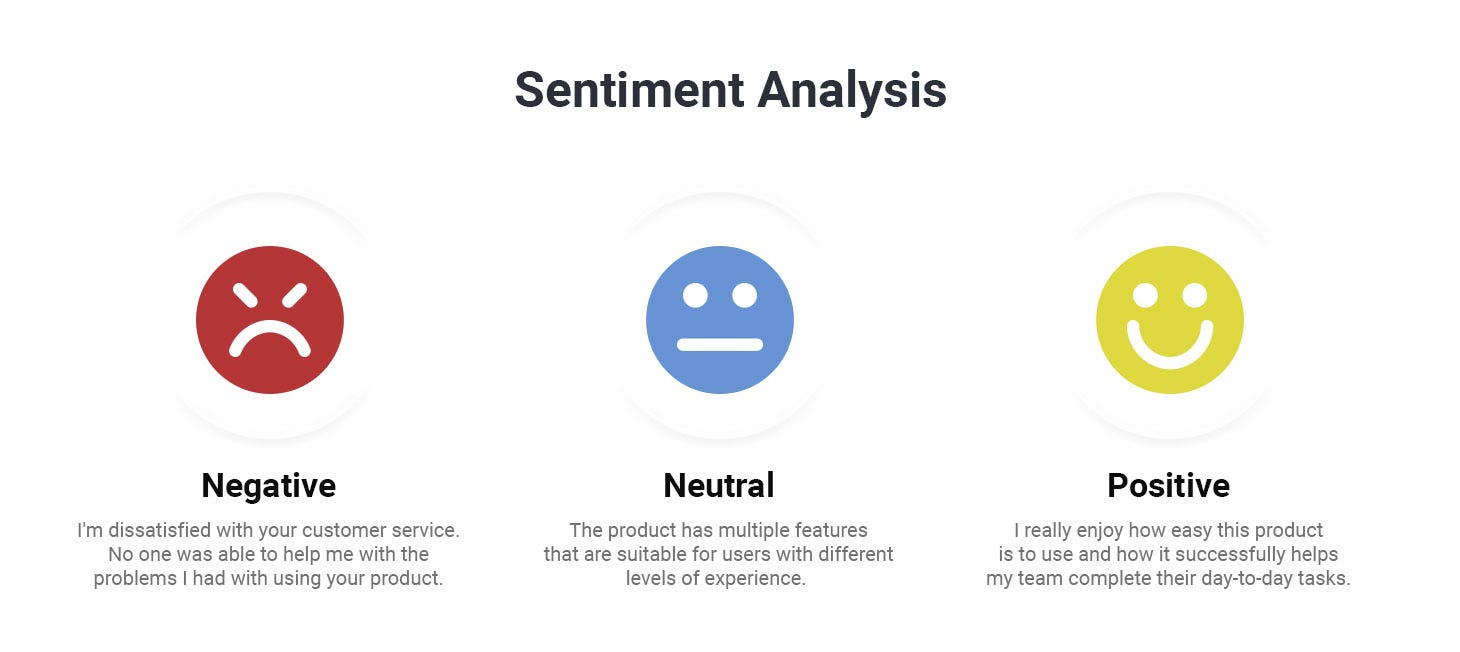

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arushchillar/disneyland-reviews")

print("Path to dataset files:", path)

c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 11.1M/11.1M [00:01<00:00, 10.1MB/s]

Extracting files...
Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\arushchillar\disneyland-reviews\versions\1


In [4]:
# Load the dataset
import pandas as pd

data = pd.read_csv('DisneylandReviews.csv', encoding='latin-1')
data

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [5]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [6]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [7]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [8]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [9]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [10]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [11]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.58       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.98      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

In [12]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones")

print("Path to dataset files:", path)

100%|██████████| 32.6M/32.6M [00:02<00:00, 13.0MB/s]

Extracting files...


Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\PromptCloudHQ\amazon-reviews-unlocked-mobile-phones\versions\1


In [13]:
# Task 1 (part 1): load the Amazon unlocked phones reviews

import os
import glob
import pandas as pd

# Use a local / Colab copy of the file if it exists, otherwise download it from Kaggle
candidates = ['Amazon_Unlocked_Mobile.csv', '/content/Amazon_Unlocked_Mobile.csv']
csv_path = next((p for p in candidates if os.path.exists(p)), None)

if csv_path is None:
    import kagglehub
    folder = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones")
    csv_path = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]

phones = pd.read_csv(csv_path)
print(phones.shape)
phones.head()

(413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [14]:
# Check for missing values and drop rows without a review or a rating
print(phones.isna().sum())
phones = phones.dropna(subset=['Reviews', 'Rating']).copy()

# The dataset is large (400k+ reviews). To keep the run time short we use a random sample.
# Set SAMPLE_SIZE = None to use every review.
SAMPLE_SIZE = 50000
if SAMPLE_SIZE:
    phones = phones.sample(n=min(SAMPLE_SIZE, len(phones)), random_state=42).reset_index(drop=True)

# Map star ratings to the three classes: positive / negative / neutral
phones['Sentiment'] = phones['Rating'].apply(
    lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))

print(phones['Sentiment'].value_counts())

Product Name        0
Brand Name      65171
Price            5933
Rating              0
Reviews            70
Review Votes    12296
dtype: int64
Sentiment
positive    34438
negative    11769
neutral      3793
Name: count, dtype: int64


### Task 1 (part 2): 5 pre-processing steps

1. Convert the text to **lower case**
2. Remove **HTML tags and URLs**
3. Remove **punctuation, numbers and special characters**
4. Remove **stop words** (we keep negations such as *not* and *no*, because they change the sentiment)
5. **Lemmatize** the words (phones -> phone, working -> work)

In [15]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor', 'never'}
lemmatizer = WordNetLemmatizer()

def preprocess_review(text):
    text = str(text).lower()                               # 1. lower case
    text = re.sub(r'<.*?>', ' ', text)                     # 2. remove HTML tags
    text = re.sub(r'http\S+|www\.\S+', ' ', text)          #    and URLs
    text = re.sub(r'[^a-z\s]', ' ', text)                 # 3. remove punctuation, numbers, special characters
    tokens = [w for w in text.split() if w not in stop_words]   # 4. remove stop words
    tokens = [lemmatizer.lemmatize(w) for w in tokens]     # 5. lemmatization
    return ' '.join(tokens)

phones['Clean_Review'] = phones['Reviews'].apply(preprocess_review)
phones[['Reviews', 'Clean_Review', 'Sentiment']].head()

,Reviews,Clean_Review,Sentiment
0,I needed a texting phone that did not require ...,needed texting phone not require data plan als...,negative
1,Excellent!,excellent,positive
2,I recommend this excellent team for the many d...,recommend excellent team many differentiating ...,positive
3,updated review. Purchased this phone on Novemb...,updated review purchased phone november worked...,positive
4,battery fail,battery fail,neutral


### Task 2: Train / test split

In [16]:
from sklearn.model_selection import train_test_split

# Drop reviews that became empty after cleaning
phones = phones[phones['Clean_Review'].str.strip() != ''].reset_index(drop=True)

# 80% train / 20% test. stratify keeps the class proportions the same in both sets.
X_train_text, X_test_text, y_train, y_test = train_test_split(
    phones['Clean_Review'], phones['Sentiment'],
    test_size=0.2, random_state=42, stratify=phones['Sentiment'])

print("Train size:", X_train_text.shape[0])
print("Test size :", X_test_text.shape[0])

Train size: 39908
Test size : 9977


### Task 3: Feature extraction with TF-IDF

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

# Learn the vocabulary on the TRAIN set only, then transform both sets
X_train_vec = tfidf.fit_transform(X_train_text)
X_test_vec = tfidf.transform(X_test_text)

print("Train matrix shape:", X_train_vec.shape)
print("Test matrix shape :", X_test_vec.shape)

Train matrix shape: (39908, 5000)
Test matrix shape : (9977, 5000)


### Task 4: Train a Naive Bayes classifier

In [18]:
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB()
nb_classifier.fit(X_train_vec, y_train)

nb_predictions = nb_classifier.predict(X_test_vec)
print("Model trained.")

Model trained.


### Task 5: Evaluate the model on the test set

In [19]:
from sklearn.metrics import accuracy_score, classification_report

print(f"Accuracy: {accuracy_score(y_test, nb_predictions):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, nb_predictions, zero_division=0))

Accuracy: 0.833

Classification Report:
              precision    recall  f1-score   support

    negative       0.81      0.69      0.75      2353
     neutral       0.31      0.01      0.03       758
    positive       0.84      0.97      0.90      6866

    accuracy                           0.83      9977
   macro avg       0.65      0.56      0.56      9977
weighted avg       0.79      0.83      0.80      9977



### Task 6: Confusion matrix

[[1633    4  716]
 [ 195   11  552]
 [ 176   21 6669]]


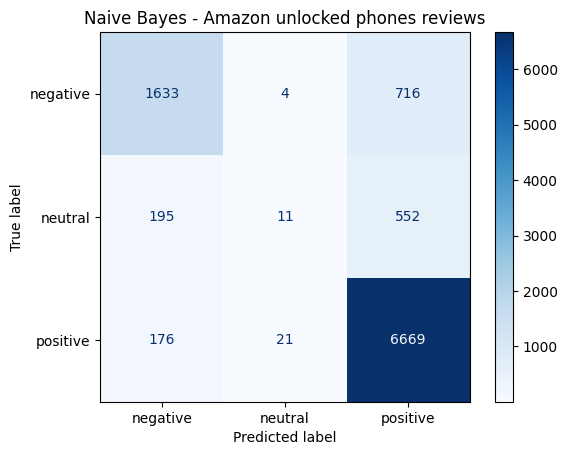

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(y_test, nb_predictions, labels=labels)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues')
plt.title("Naive Bayes - Amazon unlocked phones reviews")
plt.show()

**How to read the results**

- Rows of the confusion matrix are the **true** classes and columns are the **predicted** classes. The diagonal contains the correct predictions.
- The dataset is **imbalanced**: most reviews are positive (4-5 stars). Naive Bayes therefore tends to predict *positive* more often, and the **neutral** class (3 stars) is the hardest to recognise, so check its precision and recall in the classification report and not only the overall accuracy.